# Phase 7 F1 learning-rate mini-sweep results

This public notebook reports aggregate validation results from two independent full-data F1 runs at `5e-6` and `2e-5`, compared with the existing `1e-5` reference. It contains no audio, manifests, identifiers, prediction-level outputs, or model weights. The test set was not used.


## Result contract

All runs used the frozen 3,629-clip training set and 732-clip validation set. Validation used batch 8, explicit attention masks, `task="transcribe"`, greedy decoding, and repetition penalty `1.08`. The model revision and aggregate histories are recorded in `docs/PHASE7_F1_LR_RESULTS_AGGREGATE.json`.


In [ ]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

ROOT = Path("..")
aggregate = json.loads((ROOT / "docs" / "PHASE7_F1_LR_RESULTS_AGGREGATE.json").read_text())
summary = pd.DataFrame([
    {"run":"5e-6", "learning_rate":5e-6, "best_epoch":3, "best_CER_percent":51.05477337574255, "S":15212, "D":5021, "I":12512, "EOS_count":732, "cap_without_EOS":0},
    {"run":"1e-5 reference", "learning_rate":1e-5, "best_epoch":3, "best_CER_percent":48.391723965885525, "S":14542, "D":5739, "I":10756, "EOS_count":732, "cap_without_EOS":0},
    {"run":"2e-5", "learning_rate":2e-5, "best_epoch":5, "best_CER_percent":47.23950293902116, "S":14503, "D":5583, "I":10212, "EOS_count":732, "cap_without_EOS":0},
])
display(summary)
print({"validation_clips":732, "train_clips":3629, "test_data_used":False, "selected_run":"2e-5", "selected_epoch":5})


,run,learning_rate,epoch,training_loss,validation_CER_percent,S,D,I,EOS_count,cap_without_EOS,U+FFFD,epoch_minutes,validation_minutes,peak_MiB
0,5e-6,0.0,1,2.8174,54.3867,16751,4316,13815,731,1,1,6.3027,3.1783,2189.6465
1,5e-6,0.0,2,1.3990,52.1400,15326,5771,12344,732,0,0,6.0686,3.0375,2189.6465
2,5e-6,0.0,3,1.1458,51.0548,15212,5021,12512,732,0,0,6.0651,3.0462,2189.6465
3,5e-6,0.0,4,1.0114,53.2735,15615,5109,13444,732,0,0,6.1505,3.1291,2189.6465
4,5e-6,0.0,5,0.8880,51.0938,15156,4798,12816,731,1,0,6.0857,3.0595,2189.6465
5,5e-6,0.0,6,0.8057,53.6991,15469,5950,13022,731,1,0,6.1613,3.1251,2189.6465
6,2e-5,0.0,1,2.1545,55.7666,14391,8485,12891,732,0,0,6.0327,2.9741,2189.6099
7,2e-5,0.0,2,1.0427,48.7082,14099,6498,10643,732,0,0,5.9691,2.9110,2189.6099
8,2e-5,0.0,3,0.7448,48.3044,14708,5095,11178,732,0,0,5.9999,2.9446,2189.6099
9,2e-5,0.0,4,0.5472,48.5180,14643,6419,10056,732,0,1,6.0082,2.9698,2189.6099


,run,learning_rate,best_epoch,best_CER_percent,S,D,I,EOS_count,cap_without_EOS,peak_MiB,runtime_minutes,training_loss
0,5e-6,0.0,3,51.0548,15212,5021,12512,732,0,2189.6465,36.8339,NaN
1,1e-5 reference,0.0,3,48.3917,14542,5739,10756,732,0,3558.4302,38.4708,0.927
2,2e-5,0.0,5,47.2395,14503,5583,10212,732,0,2190.6333,48.0045,NaN


Validation-only winner: 2e-5 CER 47.2395 %
The sealed test set remains untouched; this table is for validation selection only.


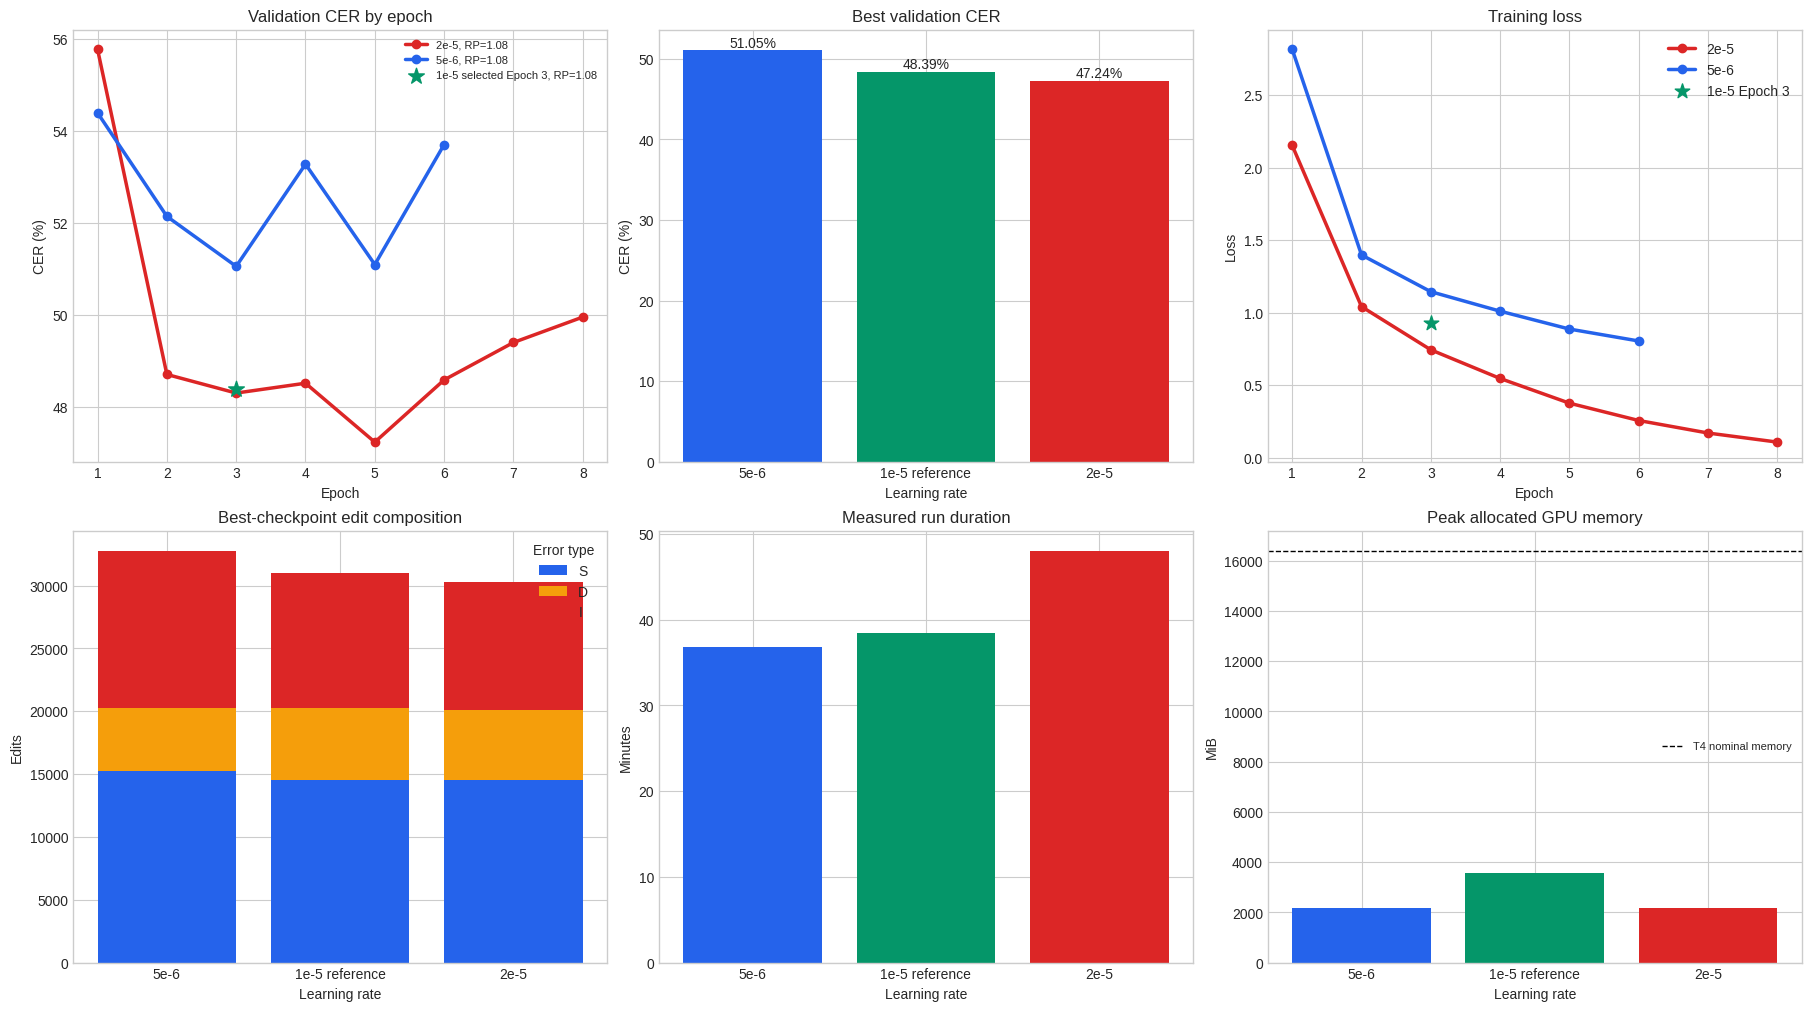

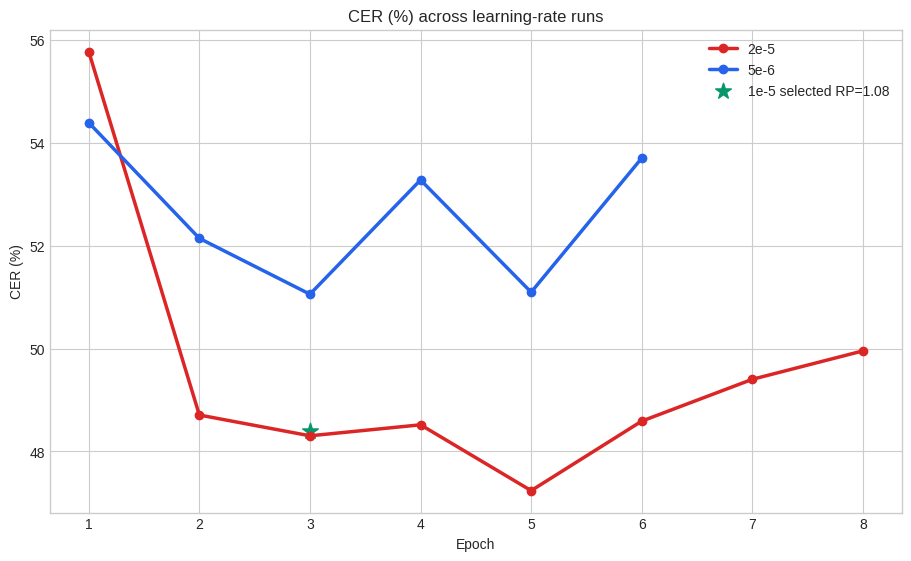

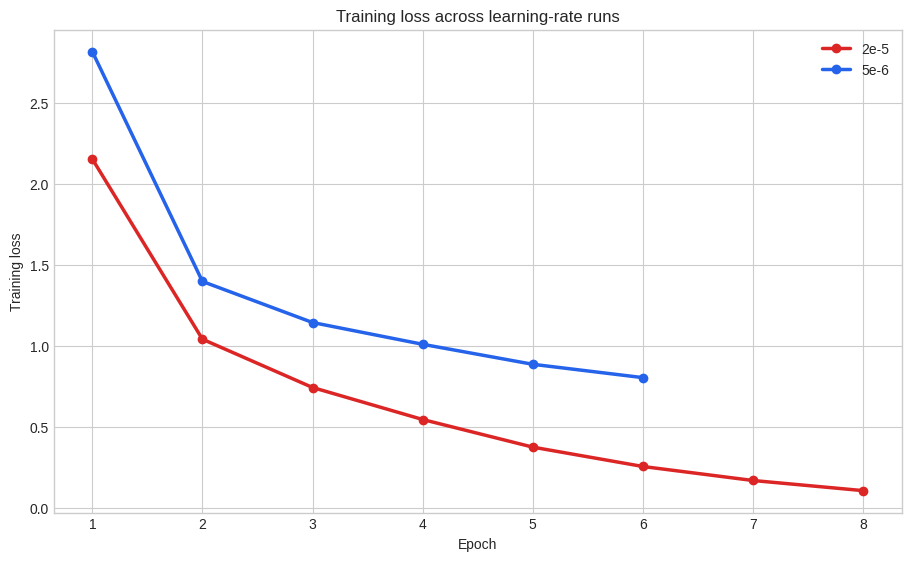

In [ ]:
from pathlib import Path
from IPython.display import Image, display

ROOT = Path("..")
for name in ["lr_sweep_comparison_dashboard.png", "cer_curves.png", "training_loss_curves.png"]:
    print(name)
    display(Image(filename=str(ROOT / "assets" / "phase7_f1_learning_rate" / name)))


## Interpretation

The `2e-5` run is the current validation-selected candidate at Epoch 5 and 47.23950% CER. The lower-rate run peaked at Epoch 3 and then oscillated. The higher-rate run continued improving through Epoch 5 and then showed validation deterioration despite falling training loss, so its final Epoch 8 checkpoint is not selected.

These are validation-only results. The next experiment is the independently initialized LoRA comparison; the sealed 683-clip test set remains untouched.
